In [1]:
from dotenv import load_dotenv
import os
load_dotenv()

# Verify it loaded
print("API key set:", "Yes" if os.getenv('NVIDIA_API_KEY') else "No")

API key set: Yes


In [2]:
import sys
sys.path.append('standalone_tools')

from climate_tools_simple import (
    load_climate_data,
    calculate_statistics,
    filter_by_country,
    find_extreme_years,
    create_visualization,
    list_countries
)

In [3]:
import pandas as pd

df = load_climate_data("resources/climate_data/temperature_annual.csv")
print(f"Loaded {len(df)} temperature records")
print(f"Years covered: {df['year'].min()}-{df['year'].max()}")
print(f"Countries: {df['country_name'].nunique()}")

Loaded 16598 temperature records
Years covered: 1940-2025
Countries: 193


In [4]:
print(calculate_statistics.__doc__)

Temperature statistics globally or for one country, as a JSON string.

    Keys: mean_temperature, min_temperature, max_temperature, std_deviation (°C),
    num_records, trend_per_decade (°C/decade), years_analyzed, and country if given.
    


In [5]:
# Calculate global climate statistics
global_stats = calculate_statistics(df)
print("Global temperature statistics:")
print(global_stats)

Global temperature statistics:
{"mean_temperature": 18.15, "min_temperature": -21.53, "max_temperature": 29.79, "std_deviation": 8.73, "num_records": 16598, "years_analyzed": "1940-2025", "trend_per_decade": 0.206}


In [6]:
print(create_visualization.__doc__)

Create a temperature chart, save it to save_path and return a summary message.

    plot_type:
      - "annual_trend": average temperature across all countries in df per year,
        with a rolling average
      - "country_comparison": one line per country in `countries`
      - "anomaly": bars of the average temperature anomaly per year
        (red above the baseline, blue below)
    


In [7]:
# Create a global temperature trend visualization
result = create_visualization(df, plot_type="annual_trend", save_path="global_trend.png")
print(result)

Saved annual_trend plot to global_trend.png


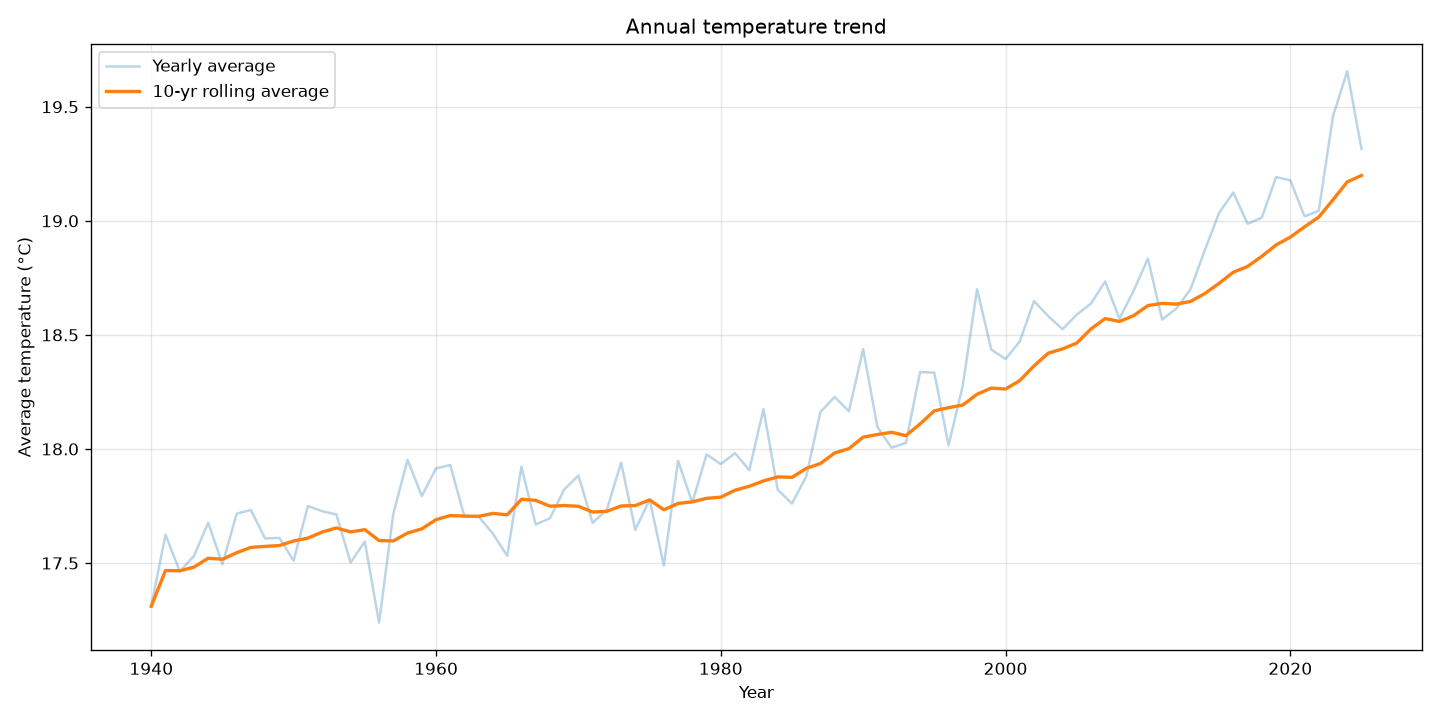

In [8]:
# Display the plot
from IPython.display import Image
Image("global_trend.png")

In [9]:
from pydantic import BaseModel, Field

class CalculateStatsInput(BaseModel):
    country: str = Field(
        default="",
        description="Country name to filter by (e.g., 'United States', 'France'). Leave empty for global statistics."
    )

In [10]:
from nat.data_models.function import FunctionBaseConfig

class CalculateStatisticsConfig(FunctionBaseConfig, name="simple_calculate_statistics"):  
    """Configuration for calculating climate statistics."""
    pass

In [11]:
from nat.builder.builder import Builder
from nat.builder.function_info import FunctionInfo
from nat.cli.register_workflow import register_function

DATA_PATH = "resources/climate_data/temperature_annual.csv"

@register_function(config_type=CalculateStatisticsConfig)
async def calculate_statistics_tool(config: CalculateStatisticsConfig, builder: Builder):
    """Register tool for calculating climate statistics."""
    df = load_climate_data(DATA_PATH)

    async def _wrapper(country: str = "") -> str:
        country_param = None if country == "" else country
        result = calculate_statistics(df, country_param)
        return result

    yield FunctionInfo.from_fn(
        _wrapper,
        input_schema=CalculateStatsInput,
        description=("Calculate temperature statistics globally or for a specific country. "
                     "Returns JSON with: mean_temperature (°C), min_temperature (°C), max_temperature (°C), "
                     "std_deviation (°C), num_records (count), trend_per_decade (°C/decade), "
                     "years_analyzed (e.g. '1950-2025'), and country (if specified).")
    )

/Users/hobbes/workspace/github.com/prakhar-kt/nat_projects/.venv/lib/python3.12/site-packages/nat/authentication/credential_validator/bearer_token_validator.py:25: AuthlibDeprecationWarning: authlib.jose module is deprecated, please use joserfc instead.
It will be compatible before version 2.0.0.
  from authlib.jose import JsonWebKey


In [12]:
!cat simple_tool_demo/src/simple_tool_demo/configs/config.yml

functions:
  calculate_statistics:
    _type: simple_calculate_statistics

llms:
  nim_llm:
    _type: nim
    model_name: nvidia/nemotron-3.5-lightning-30b-a3b
    temperature: 0.0
    chat_template_kwargs:
      enable_thinking: false

workflow:
  _type: react_agent
  llm_name: nim_llm
  tool_names: [calculate_statistics]
  verbose: true


In [13]:
%%capture
# Install our simple tool demo package into this notebook's environment
%pip install -e simple_tool_demo

In [14]:
# Use the nat CLI from this notebook's environment (plain `nat` may not be on PATH)
!{sys.prefix}/bin/nat run \
  --config_file simple_tool_demo/src/simple_tool_demo/configs/config.yml \
  --input "What is the global temperature trend per decade?"

/Users/hobbes/workspace/github.com/prakhar-kt/nat_projects/.venv/lib/python3.12/site-packages/nat/authentication/credential_validator/bearer_token_validator.py:25: AuthlibDeprecationWarning: authlib.jose module is deprecated, please use joserfc instead.
It will be compatible before version 2.0.0.
  from authlib.jose import JsonWebKey
2026-09-28 17:28:15 - INFO     - nat.cli.commands.start:192 - Starting NAT from config file: 'simple_tool_demo/src/simple_tool_demo/configs/config.yml'
/opt/anaconda3/lib/python3.12/contextlib.py:210: UserWarning: WARNING! chat_template_kwargs is not default parameter.
                chat_template_kwargs was transferred to model_kwargs.
                Please confirm that chat_template_kwargs is what you intended.
  return await anext(self.gen)

Configuration Summary:
--------------------
Workflow Type: react_agent
Number of Functions: 1
Number of Function Groups: 0
Number of LLMs: 1
Number of Embedders: 0
Number of Memory: 0
Number of Object Stores: 0
Nu

In [15]:
# Uninstall our simple tool demo package
%pip uninstall simple_tool_demo -y

Found existing installation: simple_tool_demo 0.1.0
Uninstalling simple_tool_demo-0.1.0:
  Successfully uninstalled simple_tool_demo-0.1.0
Note: you may need to restart the kernel to use updated packages.


In [16]:
!cat climate_analyzer/src/climate_analyzer/configs/config.yml

functions:
  list_countries:
    _type: list_countries
  calculate_statistics:
    _type: calculate_statistics
  find_extreme_years:
    _type: find_extreme_years
  create_visualization:
    _type: create_visualization
    output_dir: "."

llms:
  nim_llm:
    _type: nim
    model_name: nvidia/nemotron-3.5-lightning-30b-a3b
    temperature: 0.0
    chat_template_kwargs:
      enable_thinking: false

workflow:
  _type: react_agent
  llm_name: nim_llm
  tool_names: [list_countries, calculate_statistics, find_extreme_years, create_visualization]
  verbose: true


In [17]:
%%capture
# Install the package early so it's ready for all subsequent cells
%pip install -e climate_analyzer